<a href="https://colab.research.google.com/github/bestza01/DaTa-MiNiNg-/blob/main/Trainmodel0_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/database.csv')
df.head()

/tmp/ipykernel_914/1732841014.py:3: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/database.csv')


,Record ID,Agency Code,Agency Name,Agency Type,City,State,Year,Month,Incident,Crime Type,...,Victim Ethnicity,Perpetrator Sex,Perpetrator Age,Perpetrator Race,Perpetrator Ethnicity,Relationship,Weapon,Victim Count,Perpetrator Count,Record Source
0,1,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,January,1,Murder or Manslaughter,...,Unknown,Male,15,Native American/Alaska Native,Unknown,Acquaintance,Blunt Object,0,0,FBI
1,2,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,March,1,Murder or Manslaughter,...,Unknown,Male,42,White,Unknown,Acquaintance,Strangulation,0,0,FBI
2,3,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,March,2,Murder or Manslaughter,...,Unknown,Unknown,0,Unknown,Unknown,Unknown,Unknown,0,0,FBI
3,4,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,April,1,Murder or Manslaughter,...,Unknown,Male,42,White,Unknown,Acquaintance,Strangulation,0,0,FBI
4,5,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,April,2,Murder or Manslaughter,...,Unknown,Unknown,0,Unknown,Unknown,Unknown,Unknown,0,1,FBI


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 638454 entries, 0 to 638453
Data columns (total 24 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Record ID              638454 non-null  int64 
 1   Agency Code            638454 non-null  object
 2   Agency Name            638454 non-null  object
 3   Agency Type            638454 non-null  object
 4   City                   638454 non-null  object
 5   State                  638454 non-null  object
 6   Year                   638454 non-null  int64 
 7   Month                  638454 non-null  object
 8   Incident               638454 non-null  int64 
 9   Crime Type             638454 non-null  object
 10  Crime Solved           638454 non-null  object
 11  Victim Sex             638454 non-null  object
 12  Victim Age             638454 non-null  int64 
 13  Victim Race            638454 non-null  object
 14  Victim Ethnicity       638454 non-null  object
 15  

In [ ]:
df.describe()

,Record ID,Year,Incident,Victim Age,Victim Count,Perpetrator Count
count,638454.00000,638454.000000,638454.000000,638454.000000,638454.000000,638454.000000
mean,319227.50000,1995.801102,22.967924,35.033512,0.123334,0.185224
std,184305.93872,9.927693,92.149821,41.628306,0.537733,0.585496
min,1.00000,1980.000000,0.000000,0.000000,0.000000,0.000000
25%,159614.25000,1987.000000,1.000000,22.000000,0.000000,0.000000
50%,319227.50000,1995.000000,2.000000,30.000000,0.000000,0.000000
75%,478840.75000,2004.000000,10.000000,42.000000,0.000000,0.000000
max,638454.00000,2014.000000,999.000000,998.000000,10.000000,10.000000


In [ ]:
df.shape

(638454, 24)

In [ ]:
df.isnull().sum()

,0
Record ID,0
Agency Code,0
Agency Name,0
Agency Type,0
City,0
State,0
Year,0
Month,0
Incident,0
Crime Type,0


In [77]:
df_clean = df[['Victim Age','Victim Sex','Weapon','Relationship','Crime Solved']].copy()
print(df_clean.shape)
df_clean.head()


(638454, 5)


,Victim Age,Victim Sex,Weapon,Relationship,Crime Solved
0,14,Male,Blunt Object,Acquaintance,Yes
1,43,Male,Strangulation,Acquaintance,Yes
2,30,Female,Unknown,Unknown,No
3,43,Male,Strangulation,Acquaintance,Yes
4,30,Female,Unknown,Unknown,No


In [ ]:
#ดูแถวและลบค่าว่าง
print("ดูแถวก่อนลบข้อมูล", len(df_clean))
df_clean = df_clean.dropna()
print("ดูแถวหลังลบข้อมูล", len(df_clean))

ดูแถวก่อนลบข้อมูล 638454
ดูแถวหลังลบข้อมูล 638454


In [ ]:
df_clean.isnull().sum()

,0
Victim Age,0
Victim Sex,0
Weapon,0
Relationship,0
Crime Solved,0


In [73]:
import pandas as pd

df_clean['Crime Solved'] = df['Crime Solved'].map({'Yes': 1, 'No': 0})
Y = df_clean['Crime Solved']

median_age = df_clean.loc[df_clean['Victim Age'] != 998, 'Victim Age'].median()
df_clean.loc[df_clean['Victim Age'] == 998, 'Victim Age'] = median_age

X = df_clean[['Victim Age', 'Victim Sex', 'Weapon', 'Relationship']]
X_final = pd.get_dummies(X, drop_first=True)

print("ตารางคุณลักษณะก่อนแปลง", X.shape)
print("ตารางคุณลักษณะหลังแปลง One-Hot:", X_final.shape)
print("อายุของเหยื่อ")
print(X_final['Victim Age'].describe())
print("\nจำนวนคดีที่คลี่คลายสำเร็จ (1 = สำเร็จ, 0 = ไม่สำเร็จ):")
print(Y.value_counts())

ตารางคุณลักษณะก่อนแปลง (638454, 4)
ตารางคุณลักษณะหลังแปลง One-Hot: (638454, 45)
อายุของเหยื่อ
count    638454.00000
mean         33.55677
std          17.77956
min           0.00000
25%          22.00000
50%          30.00000
75%          41.00000
max          99.00000
Name: Victim Age, dtype: float64

จำนวนคดีที่คลี่คลายสำเร็จ (1 = สำเร็จ, 0 = ไม่สำเร็จ):
Crime Solved
1    448172
0    190282
Name: count, dtype: int64


In [66]:
print(" จำนวนเพศ ")
display(df_clean['Victim Sex'].value_counts())

print("จำนวนความสัมพันธ์")
display(df_clean['Relationship'].value_counts())

 จำนวนเพศ 


,count
Victim Sex,
Male,494125
Female,143345
Unknown,984


จำนวนความสัมพันธ์


,count
Relationship,
Unknown,273013
Acquaintance,126018
Stranger,96593
Wife,23187
Friend,21945
Girlfriend,16465
Son,9904
Family,9535
Husband,8803


 จำนวนคดีจำแนกตามประเภทอาวุธ


,จำนวนคดี
Weapon,
Handgun,317484
Knife,94962
Blunt Object,67337
Firearm,46980
Unknown,33192
Shotgun,30722
Rifle,23347
Strangulation,8110
Fire,6173


/tmp/ipykernel_914/3289008529.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weapon_counts.values, y=weapon_counts.index, palette='viridis')


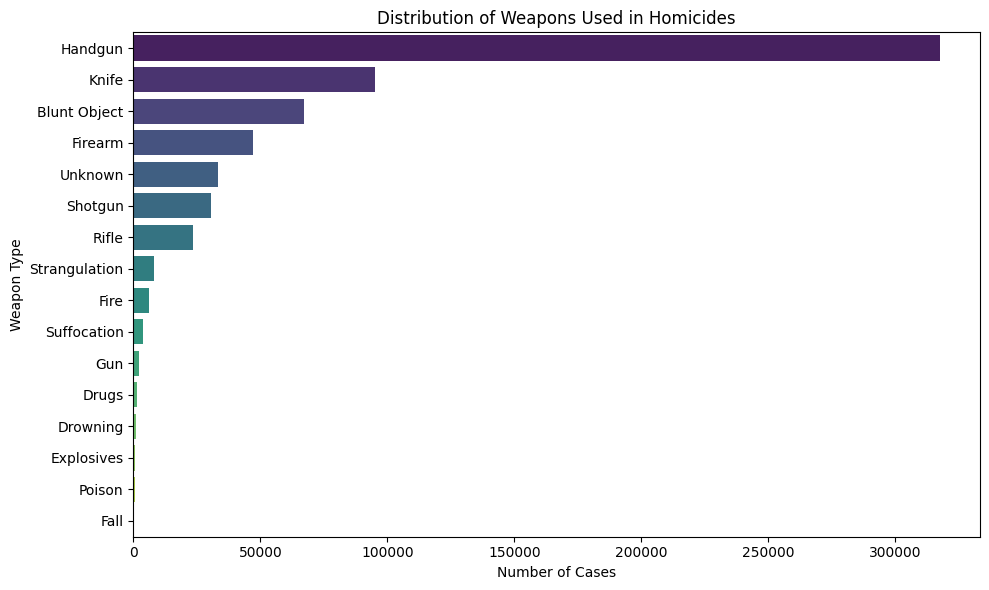

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

print(" จำนวนคดีจำแนกตามประเภทอาวุธ")
weapon_counts = df_clean['Weapon'].value_counts()
display(weapon_counts.to_frame(name='จำนวนคดี'))

plt.figure(figsize=(10, 6))
sns.barplot(x=weapon_counts.values, y=weapon_counts.index, palette='viridis')
plt.title('Distribution of Weapons Used in Homicides')
plt.xlabel('Number of Cases')
plt.ylabel('Weapon Type')
plt.tight_layout()
plt.show()

In [81]:
compare_df = pd.DataFrame({
    'ข้อมูลเดิม (Victim Sex)': X['Victim Sex'],
    'แปลงเป็นผู้ชายใช่ไหม (Victim Sex_Male)': X_final['Victim Sex_Male'].astype(int), # แปลงแสดงผลเป็น 1 หรือ 0 เพื่อความชัดเจน
    'แปลงเป็นไม่ระบุใช่ไหม (Victim Sex_Unknown)': X_final['Victim Sex_Unknown'].astype(int)
})

display(compare_df.sample(100, random_state=42))

,ข้อมูลเดิม (Victim Sex),แปลงเป็นผู้ชายใช่ไหม (Victim Sex_Male),แปลงเป็นไม่ระบุใช่ไหม (Victim Sex_Unknown)
484984,Male,1,0
608445,Male,1,0
417612,Male,1,0
372692,Male,1,0
402028,Female,0,0
...,...,...,...
609646,Male,1,0
466099,Male,1,0
608745,Male,1,0
323418,Male,1,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

df_sample = X_final.sample(n=20000, random_state=42)
y_sample = Y.loc[df_sample.index]

X_train, X_test, y_train, y_test = train_test_split(X_final,Y,test_size=0.2,random_state=42)
model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
score = accuracy_score(y_test, y_pred) * 100
print("ความแม่นยำของโมเดลคือ:", score, "%")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

ความแม่นยำของโมเดลคือ: 83.20085205691865 %
[[34373  3502]
 [17949 71867]]
              precision    recall  f1-score   support

           0       0.66      0.91      0.76     37875
           1       0.95      0.80      0.87     89816

    accuracy                           0.83    127691
   macro avg       0.81      0.85      0.82    127691
weighted avg       0.87      0.83      0.84    127691



In [ ]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier( random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
print(f"Decision Tree Accuracy: {accuracy_score(y_test, dt_pred) * 100:.2f}%")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 83.17%
              precision    recall  f1-score   support

           0       0.66      0.91      0.76     37875
           1       0.95      0.80      0.87     89816

    accuracy                           0.83    127691
   macro avg       0.81      0.85      0.82    127691
weighted avg       0.87      0.83      0.84    127691



In [ ]:
#10 ตัวแปรที่มีผลต่อการทำนายมากที่สุด
import pandas as pd

imp = pd.Series(model.feature_importances_, index=X_train.columns)
print(imp.sort_values(ascending=False).head(10))

Relationship_Unknown       0.794729
Relationship_Stranger      0.043746
Victim Age                 0.042919
Relationship_Wife          0.020624
Relationship_Friend        0.014292
Relationship_Girlfriend    0.010802
Weapon_Firearm             0.009287
Relationship_Family        0.005713
Relationship_Husband       0.005554
Weapon_Knife               0.005251
dtype: float64


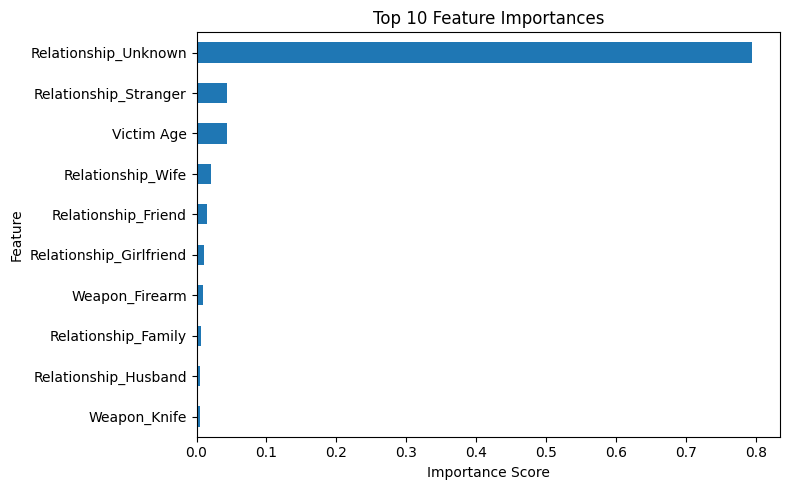

In [ ]:
import matplotlib.pyplot as plt

top10 = imp.sort_values(ascending=False).head(10).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
top10.plot(kind="barh")
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



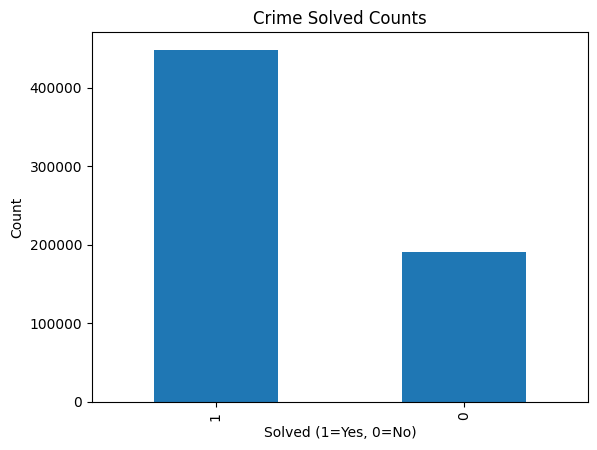

In [ ]:
import matplotlib.pyplot as plt

df_clean['Crime Solved'].value_counts().plot(kind='bar')
plt.title('Crime Solved Counts')
plt.xlabel('Solved (1=Yes, 0=No)')
plt.ylabel('Count')
plt.show()